# K-Means Clustering: Perfiles de Pacientes Hospitalarios

**Objetivo:** agrupar a los pacientes según su perfil metabólico, ponerle nombre a cada grupo y ver si algún grupo tiene más complicaciones. También revisamos la calidad de los datos.

> K-Means es **no supervisado**: la variable de complicaciones no entra al modelo. Se usa recién al final para comparar los grupos.

---
## Paso 0: Importación de librerías

| Librería | Uso |
|---|---|
| `pandas` | Manejo de tablas (DataFrames) |
| `numpy` | Operaciones numéricas |
| `matplotlib` | Gráficos base |
| `seaborn` | Gráficos estadísticos |
| `sklearn.cluster.KMeans` | Algoritmo K-Means |
| `sklearn.preprocessing.StandardScaler` | Normalización de datos |
| `sklearn.metrics.silhouette_score` | Calidad del clustering |

In [1]:
# Librerías de manipulación de datos
import pandas as pd
import numpy as np

# Librerías de visualización
import matplotlib.pyplot as plt
import seaborn as sns

# Librerías de Machine Learning
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import silhouette_score, silhouette_samples

# Configuración de estilo
import warnings
warnings.filterwarnings('ignore')            # ocultar avisos que no afectan el resultado
sns.set_style('whitegrid')
plt.rcParams['figure.figsize'] = (10, 6)
plt.rcParams['font.size'] = 11
pd.set_option('display.max_columns', None)   # mostrar todas las columnas
SEMILLA = 42                                 # semilla fija: mismos resultados en cada ejecución

print("Librerías cargadas correctamente")
print(f"   pandas  {pd.__version__}")
print(f"   numpy   {np.__version__}")

Librerías cargadas correctamente
   pandas  2.3.3
   numpy   2.2.6


---
## Paso 1: Carga y primera inspección del dataset

El dataset contiene **registros de pacientes hospitalarios de Bolivia**: datos personales, signos vitales, resultados de laboratorio, enfermedades, estado del paciente y la complicación que presentó.

In [2]:
# Cargar el dataset (el Excel debe estar en la misma carpeta que este notebook)
df = pd.read_excel('base_de_datos_medicina_complicaciones_modificada.xlsx')

print("Dataset cargado")
print(f"   Filas    : {df.shape[0]:,}")
print(f"   Columnas : {df.shape[1]}")
print()
print("Primeras 5 filas:")
df.head()

Dataset cargado
   Filas    : 10,000
   Columnas : 41

Primeras 5 filas:


,NRO_REGISTRO,CI_PACIENTE,NOMBRE,APELLIDO1,APELLIDO2,SEXO,FECHA_NACIMIENTO,EDAD,ESTADO_CIVIL,OCUPACION,NIVEL_EDUCATIVO,NIVEL_SOCIOECONOMICO,DEPARTAMENTO,CAPITAL_DEPTO,DIRECCION,TELEFONO,ASEGURAMIENTO,ESTABLECIMIENTO_SALUD,FECHA_REGISTRO,ENFERMEDADES,SINTOMAS,GRUPO_SANGUINEO,PESO_KG,ESTATURA_CM,IMC,PRESION_ARTERIAL,FRECUENCIA_CARDIACA,TEMPERATURA_C,GLUCEMIA,COLESTEROL_TOTAL,TRIGLICERIDOS,HEMOGLOBINA,CREATININA,RESULTADO_LABORATORIO,TRATAMIENTO,DIAS_HOSPITALIZACION,MEDIDA_PREVENCION,NUMERO_CONTROLES,ESTADO_PACIENTE,COMPLICACIONES,OBSERVACIONES
0,BNS-2023-000001,3341057 CB,Alex,Rivera,Herrera,M,10/08/1986,40,Soltero/a,Comerciante,Tecnico Medio,Nivel 3 - Vulnerable,Cochabamba,Cochabamba,"Zona Centro, Calle 25, Av. 21",72458591,Instituto de Seguros Sociales (CNS),Unidad Materno Infantil,24/04/2023,Asma; Diabetes Mellitus; Enfermedad Renal Cron...,Dolor de Muelas; Tos,A-,89.4,127.8,54.7,191/50,70,39.0,147,171,129,10.2,3.89,Pendiente,Consulta Externa,0,Radiografia de Torax,12,Estable,Infeccion Nosocomial,Registro generado automaticamente por el Banco...
1,BNS-2024-000002,2166941 LP,Ofelia,Miranda,Reyes,F,27/02/1992,34,Divorciado/a,Doctor/a,Ninguno,Nivel 5 - Medio,Pando,Cobija,"Zona Oeste, Calle 46, Av. 81",74823498,Instituto de Seguros Sociales (CNS),Centro de Rehabilitacion,02/05/2024,Enfermedad Renal Cronica; Cancer de Mama; Obes...,Palpitaciones; Dolor de Garganta; Erupcion Cut...,B-,113.7,170.2,39.3,167/59,71,38.2,122,141,286,11.8,4.95,Pendiente,Resonancia Magnetica,0,Examen de Orina,4,Estable,Embolia,Registro generado automaticamente por el Banco...
2,BNS-2024-000003,5443951 SC,Daniela,Arce,Martinez,F,08/01/2001,25,Soltero/a,Peluquero,Maestria,Nivel 2 - Pobreza,Oruro,Oruro,"Zona Sur, Calle 33, Av. 196",75137722,Instituto de Seguros Sociales (CNS),Unidad de Salud,05/03/2024,Hernia Discal; Vacunacion; Infecciones Urinarias,Orina Frecuente; Erupcion Cutanea; Ganancia de...,A+,134.7,115.3,101.3,100/104,58,37.4,212,219,320,10.5,2.90,Normal,Terapia Intensiva,14,Desparasitacion Semestral,4,Estable,Reaccion Adversa,Registro generado automaticamente por el Banco...
3,BNS-2024-000004,4337174 SC,Marcelo,Ramirez,Palacios,M,27/07/1935,91,Divorciado/a,Desempleado/a,Maestria,Nivel 3 - Vulnerable,Santa Cruz,Santa Cruz,"Zona Sur, Calle 29, Av. 133",77273233,Seguro Básico de Salud (SBS),Hospital Docente,10/04/2024,Parto Normal; Apendicitis,Fiebre; Dolor Toracico; Ojos Llorosos; Tos; Mareo,B+,46.4,187.8,13.2,90/60,112,39.6,254,236,114,9.3,2.53,Pendiente,Resonancia Magnetica,0,Control de Glucosa,11,Estable,Fallo Multiorgánico,Registro generado automaticamente por el Banco...
4,BNS-2023-000005,1352896 PD,Hugo,Sanchez,Rojas,M,30/12/1965,60,Casado/a,Comerciante,Educacion Inicial,Nivel 4 - Medio Bajo,Beni,Trinidad,"Zona Centro, Calle 4, Av. 104",74860684,Instituto de Seguros Sociales (CNS),Hospital Pediatrico,20/04/2023,Hipertension Arterial; Gastritis,Ganancia de Peso,O+,47.8,123.8,31.2,165/112,77,38.2,245,246,345,12.7,3.99,Positivo,Fisioterapia,0,Control Prenatal,6,Mejorando,Embolia,Registro generado automaticamente por el Banco...


In [3]:
# Información general: tipo de dato de cada columna
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 41 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   NRO_REGISTRO           10000 non-null  object 
 1   CI_PACIENTE            10000 non-null  object 
 2   NOMBRE                 10000 non-null  object 
 3   APELLIDO1              10000 non-null  object 
 4   APELLIDO2              10000 non-null  object 
 5   SEXO                   10000 non-null  object 
 6   FECHA_NACIMIENTO       10000 non-null  object 
 7   EDAD                   10000 non-null  int64  
 8   ESTADO_CIVIL           10000 non-null  object 
 9   OCUPACION              10000 non-null  object 
 10  NIVEL_EDUCATIVO        10000 non-null  object 
 11  NIVEL_SOCIOECONOMICO   10000 non-null  object 
 12  DEPARTAMENTO           10000 non-null  object 
 13  CAPITAL_DEPTO          10000 non-null  object 
 14  DIRECCION              10000 non-null  object 
 15  TEL

In [4]:
# Estadísticas descriptivas de las variables numéricas
df.describe().round(2)

,EDAD,TELEFONO,PESO_KG,ESTATURA_CM,IMC,FRECUENCIA_CARDIACA,TEMPERATURA_C,GLUCEMIA,COLESTEROL_TOTAL,TRIGLICERIDOS,HEMOGLOBINA,CREATININA,DIAS_HOSPITALIZACION,NUMERO_CONTROLES
count,10000.00,10000.00,10000.00,10000.00,9918.00,10000.00,10000.00,10000.00,10000.00,10000.00,10000.00,10000.00,10000.00,10000.00
mean,46.94,75480717.73,91.57,145.58,51.43,84.86,38.01,180.30,199.84,224.72,13.02,2.65,1.79,6.00
std,27.55,2594844.53,33.49,34.60,39.32,20.29,1.45,69.11,58.44,101.27,2.90,1.35,5.81,3.77
min,0.00,71001005.00,2.60,45.30,0.70,50.00,35.50,60.00,100.00,50.00,8.00,0.30,0.00,0.00
25%,23.00,73244662.00,64.47,120.80,28.00,67.00,36.80,121.00,149.00,136.00,10.50,1.50,0.00,3.00
50%,47.00,75411804.50,92.00,147.40,41.00,85.00,38.00,181.00,200.00,225.00,13.10,2.63,0.00,6.00
75%,71.00,77748102.00,119.20,174.12,62.78,102.25,39.30,239.00,251.00,312.00,15.60,3.82,0.00,9.00
max,95.00,79999663.00,150.00,200.00,418.00,120.00,40.50,300.00,300.00,400.00,18.00,5.00,30.00,12.00


In [5]:
# Valores nulos
nulos = df.isnull().sum()
nulos_pct = (nulos / len(df) * 100).round(2)
resumen_nulos = pd.DataFrame({'Nulos': nulos, 'Porcentaje (%)': nulos_pct})
resumen_nulos = resumen_nulos[resumen_nulos['Nulos'] > 0]   # solo columnas con nulos

if resumen_nulos.empty:
    print("No hay valores nulos en el dataset")
else:
    print("Columnas con valores nulos:")
    print(resumen_nulos)

Columnas con valores nulos:
     Nulos  Porcentaje (%)
IMC     82            0.82


**Interpretación:** hay 10,000 pacientes y 41 columnas. Solo el IMC tiene vacíos (82). En las estadísticas ya se ven valores extraños: IMC de 0.7 y de 418, estaturas de 45 cm y una creatinina promedio de 2.6 (lo normal es 0.6 a 1.3).

---
## Paso 2: Ingeniería de features

Creamos variables nuevas a partir de las existentes:

| Variable | Qué es |
|---|---|
| `IMC` (limpio) | Rellenamos vacíos con la mediana y recortamos valores imposibles al rango 10–70 |
| `PRESION_SISTOLICA` / `DIASTOLICA` | Separamos el texto "120/80" en dos números |
| `NUM_ENFERMEDADES` | Cantidad de enfermedades del paciente |
| `INTERNADO` | 1 si estuvo hospitalizado al menos un día |
| `TARGET_COMPLICACION` | 1 si tuvo alguna complicación (solo para comparar al final) |

In [6]:
# IMC: guardamos el original para revisarlo en el Paso 4
df['IMC_ORIGINAL'] = df['IMC']
df['IMC'] = df['IMC'].fillna(df['IMC'].median())   # rellenar vacíos con la mediana
df['IMC'] = df['IMC'].clip(lower=10, upper=70)     # recortar valores imposibles

# Presión arterial "120/80" -> dos columnas numéricas
presion = df['PRESION_ARTERIAL'].str.split('/', expand=True).astype(int)
df['PRESION_SISTOLICA'] = presion[0]
df['PRESION_DIASTOLICA'] = presion[1]

# Número de enfermedades (vienen separadas por ";")
df['NUM_ENFERMEDADES'] = df['ENFERMEDADES'].str.count(';') + 1

# Internado: estuvo al menos un día en el hospital
df['INTERNADO'] = (df['DIAS_HOSPITALIZACION'] > 0).astype(int)

# Complicación: 1 = tuvo alguna, 0 = "Ninguna"
df['TARGET_COMPLICACION'] = (df['COMPLICACIONES'] != 'Ninguna').astype(int)

print("Features creados:")
print(f"   IMC               -> min: {df['IMC'].min()}, max: {df['IMC'].max()}")
print(f"   PRESION_SISTOLICA -> min: {df['PRESION_SISTOLICA'].min()}, max: {df['PRESION_SISTOLICA'].max()}")
print(f"   NUM_ENFERMEDADES  -> min: {df['NUM_ENFERMEDADES'].min()}, max: {df['NUM_ENFERMEDADES'].max()}")
print(f"   INTERNADO         -> {df['INTERNADO'].sum():,} pacientes internados")

tasa_global = df['TARGET_COMPLICACION'].mean() * 100
print(f"\nPrevalencia de complicaciones (KPI del proyecto): {tasa_global:.2f}%")

# Vista de las nuevas columnas
df[['NRO_REGISTRO', 'EDAD', 'IMC', 'PRESION_SISTOLICA', 'PRESION_DIASTOLICA',
    'NUM_ENFERMEDADES', 'INTERNADO', 'TARGET_COMPLICACION']].head()

Features creados:
   IMC               -> min: 10.0, max: 70.0
   PRESION_SISTOLICA -> min: 80, max: 200
   NUM_ENFERMEDADES  -> min: 1, max: 4
   INTERNADO         -> 1,151 pacientes internados

Prevalencia de complicaciones (KPI del proyecto): 87.82%


,NRO_REGISTRO,EDAD,IMC,PRESION_SISTOLICA,PRESION_DIASTOLICA,NUM_ENFERMEDADES,INTERNADO,TARGET_COMPLICACION
0,BNS-2023-000001,40,54.7,191,50,4,0,1
1,BNS-2024-000002,34,39.3,167,59,3,0,1
2,BNS-2024-000003,25,70.0,100,104,3,1,1
3,BNS-2024-000004,91,13.2,90,60,2,0,1
4,BNS-2023-000005,60,31.2,165,112,2,0,1


---
## Paso 3: Visualización exploratoria

Antes de aplicar K-Means exploramos los datos. Comparamos cada variable con su **valor normal en adultos** (línea verde):

| Variable | Valor normal | Riesgo |
|---|---|---|
| IMC | 18.5 – 24.9 | 30 o más: obesidad |
| Glucemia (mg/dL) | 70 – 99 | 126 o más: rango de diabetes |
| Colesterol total (mg/dL) | menos de 200 | 240 o más: alto |
| Triglicéridos (mg/dL) | menos de 150 | 200 o más: alto |

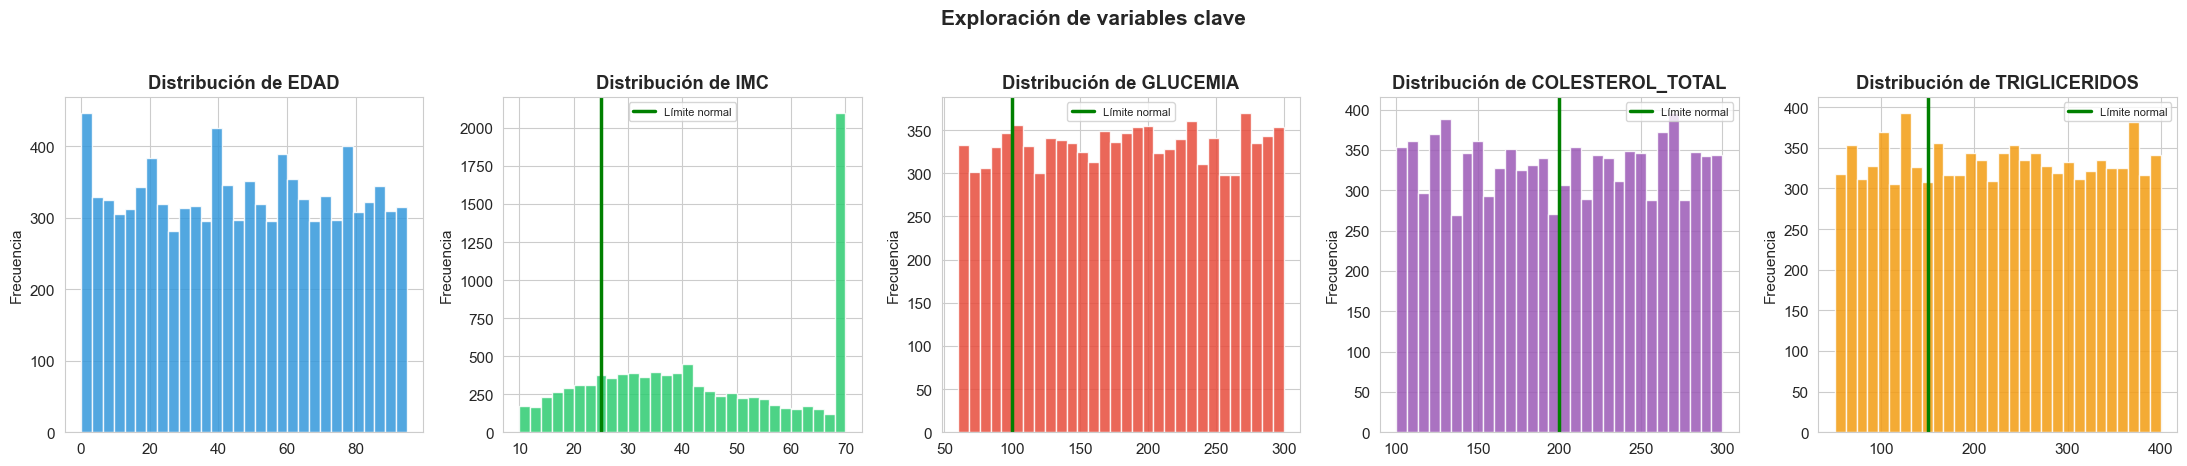

In [7]:
# Histogramas de las variables principales
features = ['EDAD', 'IMC', 'GLUCEMIA', 'COLESTEROL_TOTAL', 'TRIGLICERIDOS']
limite_normal = {'IMC': 25, 'GLUCEMIA': 100, 'COLESTEROL_TOTAL': 200, 'TRIGLICERIDOS': 150}
colores_hist = ['#3498db', '#2ecc71', '#e74c3c', '#9b59b6', '#f39c12']

fig, axes = plt.subplots(1, 5, figsize=(22, 4.5))
for ax, var, color in zip(axes, features, colores_hist):
    ax.hist(df[var], bins=30, color=color, edgecolor='white', alpha=0.85)
    if var in limite_normal:   # línea del límite normal
        ax.axvline(limite_normal[var], color='green', linewidth=2.5, label='Límite normal')
        ax.legend(fontsize=8)
    ax.set_title(f'Distribución de {var}', fontweight='bold')
    ax.set_ylabel('Frecuencia')
plt.suptitle('Exploración de variables clave', fontsize=15, fontweight='bold', y=1.03)
plt.tight_layout()
plt.show()

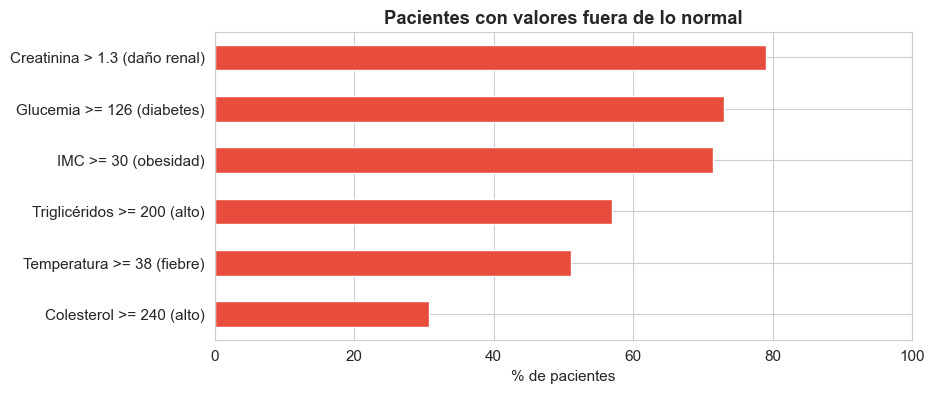

,% pacientes
IMC >= 30 (obesidad),71.4
Glucemia >= 126 (diabetes),73.0
Colesterol >= 240 (alto),30.7
Triglicéridos >= 200 (alto),57.0
Creatinina > 1.3 (daño renal),79.1
Temperatura >= 38 (fiebre),51.1


In [8]:
# Porcentaje de pacientes con valores fuera de lo normal
fuera_rango = pd.Series({
    'IMC >= 30 (obesidad)':          (df['IMC'] >= 30).mean() * 100,
    'Glucemia >= 126 (diabetes)':    (df['GLUCEMIA'] >= 126).mean() * 100,
    'Colesterol >= 240 (alto)':      (df['COLESTEROL_TOTAL'] >= 240).mean() * 100,
    'Triglicéridos >= 200 (alto)':   (df['TRIGLICERIDOS'] >= 200).mean() * 100,
    'Creatinina > 1.3 (daño renal)': (df['CREATININA'] > 1.3).mean() * 100,
    'Temperatura >= 38 (fiebre)':    (df['TEMPERATURA_C'] >= 38).mean() * 100,
}).round(1)

fuera_rango.sort_values().plot.barh(figsize=(9, 4), color='#e74c3c')
plt.xlabel('% de pacientes')
plt.xlim(0, 100)
plt.title('Pacientes con valores fuera de lo normal', fontweight='bold')
plt.show()
fuera_rango.to_frame('% pacientes')

**Interpretación:** los histogramas son **planos**: cada valor aparece casi la misma cantidad de veces, algo típico de datos generados al azar. Además, casi todos los pacientes tienen valores de riesgo: 7 de cada 10 están en rango de diabetes, 8 de cada 10 tendrían daño renal y la mitad tiene fiebre. En un hospital real esto es muy poco probable.

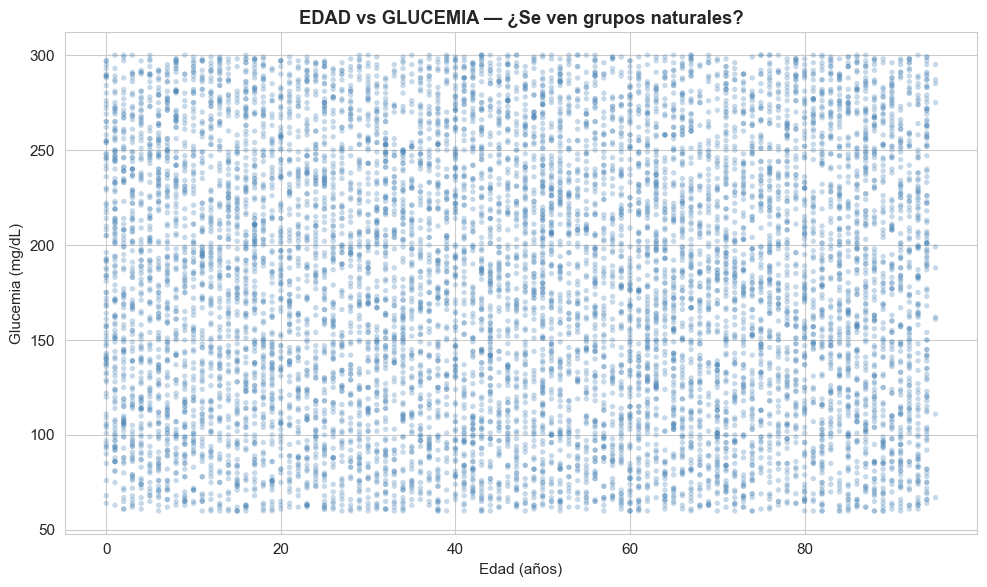

In [9]:
# Scatter: EDAD vs GLUCEMIA
# Este gráfico da una pista de si existen grupos naturales
plt.figure(figsize=(10, 6))
plt.scatter(df['EDAD'], df['GLUCEMIA'], alpha=0.3, c='steelblue', edgecolors='none', s=15)
plt.title('EDAD vs GLUCEMIA — ¿Se ven grupos naturales?', fontweight='bold')
plt.xlabel('Edad (años)')
plt.ylabel('Glucemia (mg/dL)')
plt.tight_layout()
plt.show()

**Interpretación:** los puntos llenan todo el gráfico de forma pareja. **No se ven grupos naturales**: la glucemia no cambia con la edad.

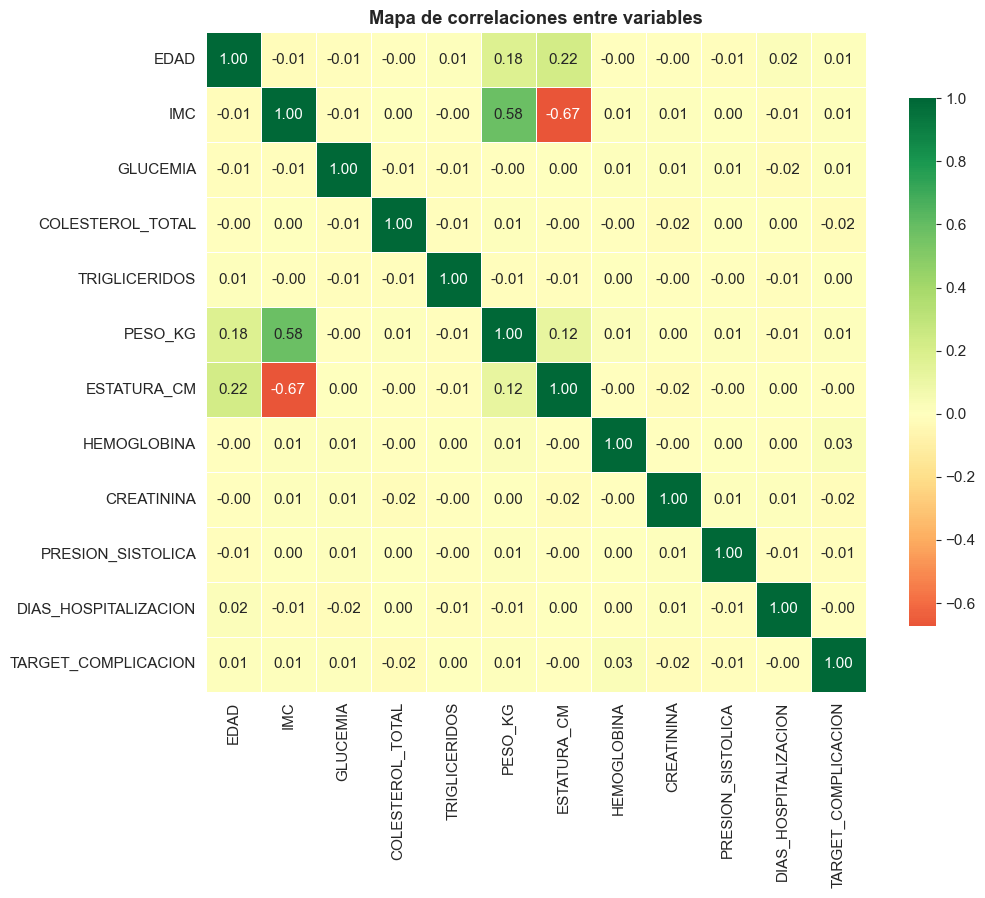

Cerca de 1.0 (verde): correlación positiva fuerte
Cerca de -1.0 (rojo): correlación negativa fuerte
Cerca de 0 (amarillo): sin relación


In [10]:
# Heatmap de correlaciones
vars_correlacion = features + ['PESO_KG', 'ESTATURA_CM', 'HEMOGLOBINA', 'CREATININA',
                               'PRESION_SISTOLICA', 'DIAS_HOSPITALIZACION', 'TARGET_COMPLICACION']

plt.figure(figsize=(11, 9))
sns.heatmap(df[vars_correlacion].corr(), annot=True, fmt='.2f', cmap='RdYlGn',
            center=0, square=True, linewidths=0.5, cbar_kws={'shrink': 0.8})
plt.title('Mapa de correlaciones entre variables', fontweight='bold')
plt.tight_layout()
plt.show()

print("Cerca de 1.0 (verde): correlación positiva fuerte")
print("Cerca de -1.0 (rojo): correlación negativa fuerte")
print("Cerca de 0 (amarillo): sin relación")

**Interpretación:** casi todas las correlaciones son cercanas a 0, es decir, las variables no tienen relación entre sí. Solo el IMC se relaciona con el peso y la estatura, porque se calcula con ellos. Las complicaciones (`TARGET_COMPLICACION`) no se relacionan con ninguna variable clínica.

---
## Paso 4: Calidad e inconsistencias de los datos

Revisamos si los datos tienen **sentido médico**: diagnósticos que no corresponden al sexo o a la edad, medidas físicas imposibles y laboratorios que no cuadran con el diagnóstico.

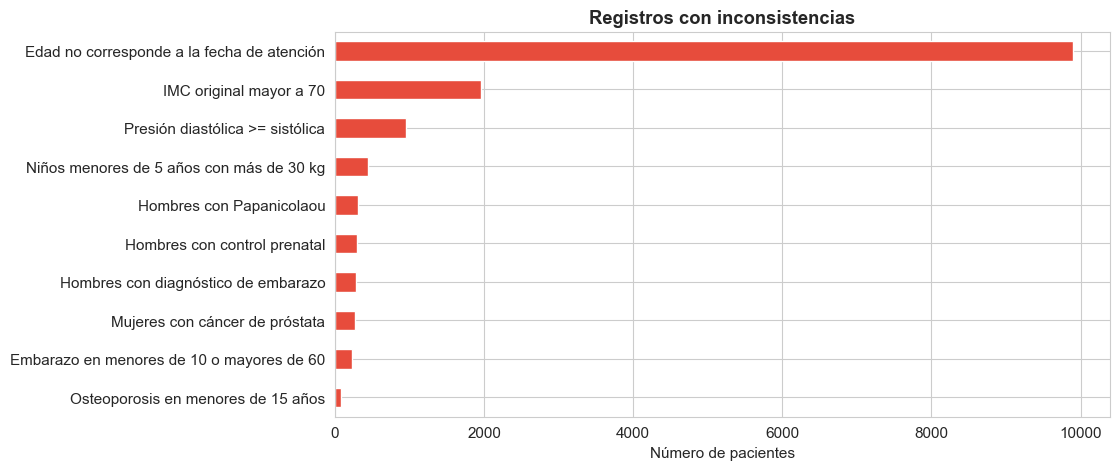

,Pacientes
Osteoporosis en menores de 15 años,78
Embarazo en menores de 10 o mayores de 60,233
Mujeres con cáncer de próstata,275
Hombres con diagnóstico de embarazo,286
Hombres con control prenatal,298
Hombres con Papanicolaou,310
Niños menores de 5 años con más de 30 kg,441
Presión diastólica >= sistólica,956
IMC original mayor a 70,1956
Edad no corresponde a la fecha de atención,9899


In [11]:
hombre = df['SEXO'] == 'M'
mujer = df['SEXO'] == 'F'
tiene = lambda enf: df['ENFERMEDADES'].str.contains(enf, regex=False)   # ¿tiene esa enfermedad?
prevencion = df['MEDIDA_PREVENCION']

# Edad que debería tener el paciente el día en que fue atendido
nacimiento = pd.to_datetime(df['FECHA_NACIMIENTO'], dayfirst=True)
registro = pd.to_datetime(df['FECHA_REGISTRO'], dayfirst=True)
edad_al_atenderse = ((registro - nacimiento).dt.days / 365.25).astype(int)

inconsistencias = pd.Series({
    'Hombres con diagnóstico de embarazo':        (hombre & tiene('Embarazo')).sum(),
    'Mujeres con cáncer de próstata':             (mujer & tiene('Cancer de Prostata')).sum(),
    'Hombres con Papanicolaou':                   (hombre & (prevencion == 'Papanicolaou')).sum(),
    'Hombres con control prenatal':               (hombre & (prevencion == 'Control Prenatal')).sum(),
    'Embarazo en menores de 10 o mayores de 60':  (tiene('Embarazo') & ((df['EDAD'] < 10) | (df['EDAD'] > 60))).sum(),
    'Osteoporosis en menores de 15 años':         (tiene('Osteoporosis') & (df['EDAD'] < 15)).sum(),
    'Niños menores de 5 años con más de 30 kg':   ((df['EDAD'] < 5) & (df['PESO_KG'] > 30)).sum(),
    'IMC original mayor a 70':                    (df['IMC_ORIGINAL'] > 70).sum(),
    'Presión diastólica >= sistólica':            (df['PRESION_DIASTOLICA'] >= df['PRESION_SISTOLICA']).sum(),
    'Edad no corresponde a la fecha de atención': ((df['EDAD'] - edad_al_atenderse).abs() > 1).sum(),
}).sort_values()

inconsistencias.plot.barh(figsize=(10, 5), color='#e74c3c')
plt.xlabel('Número de pacientes')
plt.title('Registros con inconsistencias', fontweight='bold')
plt.show()
inconsistencias.to_frame('Pacientes')

**Interpretación:** se encontraron registros **imposibles**:
- Hombres embarazados, con Papanicolaou o con control prenatal, y mujeres con cáncer de próstata.
- Embarazos en niñas menores de 10 años o en mujeres mayores de 60, y osteoporosis en niños.
- 441 niños menores de 5 años pesan más de 30 kg, y 1,956 pacientes tenían un IMC mayor a 70.
- 956 pacientes tienen la presión diastólica (número de abajo) igual o mayor que la sistólica.
- La EDAD no corresponde a la fecha de atención: está calculada al año 2026 (ver abajo).

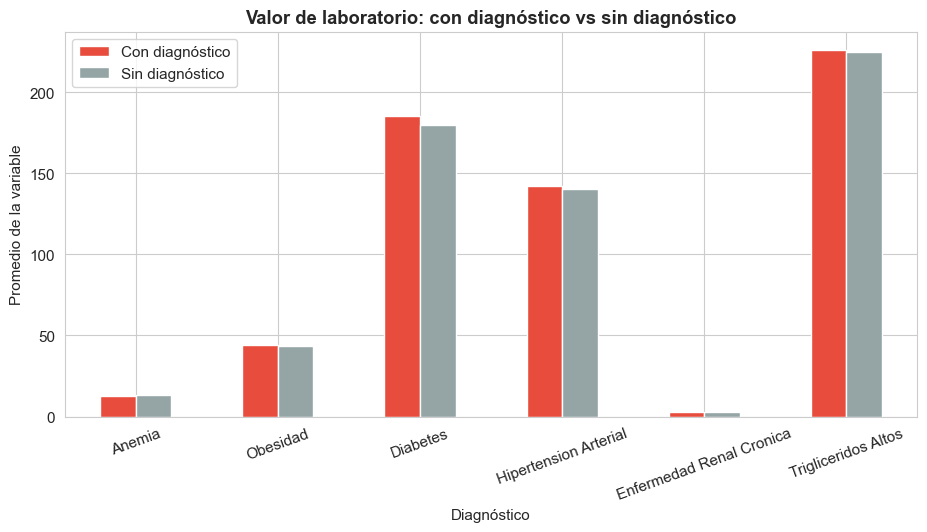

,Diagnóstico,Variable,Con diagnóstico,Sin diagnóstico
0,Anemia,HEMOGLOBINA,12.8,13.0
1,Obesidad,IMC,43.9,43.6
2,Diabetes,GLUCEMIA,185.4,180.1
3,Hipertension Arterial,PRESION_SISTOLICA,142.1,140.1
4,Enfermedad Renal Cronica,CREATININA,2.7,2.6
5,Trigliceridos Altos,TRIGLICERIDOS,226.2,224.6


In [12]:
# ¿El diagnóstico coincide con el laboratorio?
# Ejemplo: un paciente con anemia debería tener la hemoglobina más BAJA que los demás
comparaciones = [('Anemia', 'HEMOGLOBINA'), ('Obesidad', 'IMC'), ('Diabetes', 'GLUCEMIA'),
                 ('Hipertension Arterial', 'PRESION_SISTOLICA'),
                 ('Enfermedad Renal Cronica', 'CREATININA'),
                 ('Trigliceridos Altos', 'TRIGLICERIDOS')]

filas = []
for enf, var in comparaciones:
    filas.append({'Diagnóstico': enf, 'Variable': var,
                  'Con diagnóstico': df.loc[tiene(enf), var].mean(),
                  'Sin diagnóstico': df.loc[~tiene(enf), var].mean()})
diag_vs_lab = pd.DataFrame(filas).round(1)

# Gráfico: si los datos fueran reales, las barras serían muy distintas
diag_vs_lab.set_index('Diagnóstico')[['Con diagnóstico', 'Sin diagnóstico']].plot.bar(
    figsize=(11, 5), color=['#e74c3c', '#95a5a6'], rot=20)
plt.title('Valor de laboratorio: con diagnóstico vs sin diagnóstico', fontweight='bold')
plt.ylabel('Promedio de la variable')
plt.show()
diag_vs_lab

In [13]:
# En la realidad los hombres son más altos y tienen más hemoglobina que las mujeres
df.groupby('SEXO')[['ESTATURA_CM', 'PESO_KG', 'HEMOGLOBINA']].mean().round(1)

,ESTATURA_CM,PESO_KG,HEMOGLOBINA
SEXO,,,
F,145.5,91.8,13.1
M,145.6,91.3,13.0


In [14]:
# En cambio, los datos sociales sí respetan reglas lógicas
ninos = df['EDAD'] < 12
print("Niños < 12 años con maestría o doctorado:", (ninos & df['NIVEL_EDUCATIVO'].isin(['Maestria', 'Doctorado'])).sum())
print("Niños < 12 años jubilados:              ", (ninos & (df['OCUPACION'] == 'Jubilado/a')).sum())
print("Menores de 15 casados o viudos:         ", ((df['EDAD'] < 15) & df['ESTADO_CIVIL'].isin(['Casado/a', 'Viudo/a'])).sum())

# ¿A qué fecha está calculada la EDAD? Probamos con el 1 de enero de 2026
edad_2026 = ((pd.Timestamp('2026-01-01') - nacimiento).dt.days / 365.25).astype(int)
print(f"\nEDAD coincide con la edad al 2026: {((df['EDAD'] - edad_2026).abs() <= 1).mean() * 100:.0f}% de los registros")
print(f"Fechas de atención: {registro.min().date()} a {registro.max().date()}")
print("\nObservación de todos los registros:", df['OBSERVACIONES'].unique()[0])

Niños < 12 años con maestría o doctorado: 0
Niños < 12 años jubilados:               0
Menores de 15 casados o viudos:          0

EDAD coincide con la edad al 2026: 100% de los registros
Fechas de atención: 2020-01-01 a 2024-12-05

Observación de todos los registros: Registro generado automaticamente por el Banco Nacional de Salud de Bolivia


**Interpretación:**
- **El diagnóstico no cambia el laboratorio:** en el gráfico, las barras roja y gris son casi iguales. Un paciente con anemia tiene la misma hemoglobina que uno sin anemia (12.8 vs 13.0). En datos reales la diferencia sería grande.
- **Hombres y mujeres son iguales** en estatura, peso y hemoglobina. En la realidad, los hombres son más altos y tienen más hemoglobina.
- **Los datos sociales sí son coherentes:** no hay niños con doctorado, jubilados ni casados. Quien generó la base cuidó las reglas sociales, pero no las médicas.
- La EDAD está calculada al 2026 aunque las atenciones son de 2020–2024, y todos los registros dicen *"generado automáticamente"*.

**Conclusión del paso:** hay evidencia fuerte de que el dataset es **simulado**, no de un hospital real.

---
## Paso 5: Preprocesamiento

### ¿Por qué preprocesar?
K-Means agrupa usando **distancias**. Si una variable tiene valores grandes (triglicéridos: 50–400) y otra pequeños (IMC: 10–70), la grande dominaría el resultado.

### Solución: StandardScaler
Transforma cada variable para que tenga **media = 0** y **desviación = 1**:

$$z = \frac{x - \mu}{\sigma}$$

### Features seleccionados para clustering
| Variable | Justificación |
|---|---|
| `EDAD` | Factor de riesgo general |
| `IMC` | Resume peso y estatura (por eso no usamos esas dos) |
| `GLUCEMIA` | Azúcar en sangre (diabetes) |
| `COLESTEROL_TOTAL` | Riesgo cardiovascular |
| `TRIGLICERIDOS` | Grasas en sangre |

No usamos datos personales (nombre, CI, teléfono) ni `COMPLICACIONES`.

In [15]:
# Selección de features para clustering
X = df[features].copy()

print(f"Datos para clustering: {X.shape[0]:,} registros")
print(f"   Nulos restantes: {X.isnull().sum().sum()}")
X.describe().round(2)

Datos para clustering: 10,000 registros
   Nulos restantes: 0


,EDAD,IMC,GLUCEMIA,COLESTEROL_TOTAL,TRIGLICERIDOS
count,10000.00,10000.00,10000.00,10000.00,10000.00
mean,46.94,43.58,180.30,199.84,224.72
std,27.55,18.72,69.11,58.44,101.27
min,0.00,10.00,60.00,100.00,50.00
25%,23.00,28.10,121.00,149.00,136.00
50%,47.00,41.00,181.00,200.00,225.00
75%,71.00,62.50,239.00,251.00,312.00
max,95.00,70.00,300.00,300.00,400.00


In [16]:
# Aplicar StandardScaler
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)
X_scaled_df = pd.DataFrame(X_scaled, columns=features)   # a tabla para poder verlo

print("ANTES (valores originales):")
print(X.describe().round(2).loc[['mean', 'std', 'min', 'max']].to_string())
print()
print("DESPUÉS (valores escalados):")
print(X_scaled_df.describe().round(2).loc[['mean', 'std', 'min', 'max']].to_string())
print()
print("Ahora todas las variables tienen media = 0 y desviación = 1")

ANTES (valores originales):
       EDAD    IMC  GLUCEMIA  COLESTEROL_TOTAL  TRIGLICERIDOS
mean  46.94  43.58    180.30            199.84         224.72
std   27.55  18.72     69.11             58.44         101.27
min    0.00  10.00     60.00            100.00          50.00
max   95.00  70.00    300.00            300.00         400.00

DESPUÉS (valores escalados):
      EDAD   IMC  GLUCEMIA  COLESTEROL_TOTAL  TRIGLICERIDOS
mean  0.00 -0.00      0.00              0.00           0.00
std   1.00  1.00      1.00              1.00           1.00
min  -1.70 -1.79     -1.74             -1.71          -1.73
max   1.74  1.41      1.73              1.71           1.73

Ahora todas las variables tienen media = 0 y desviación = 1


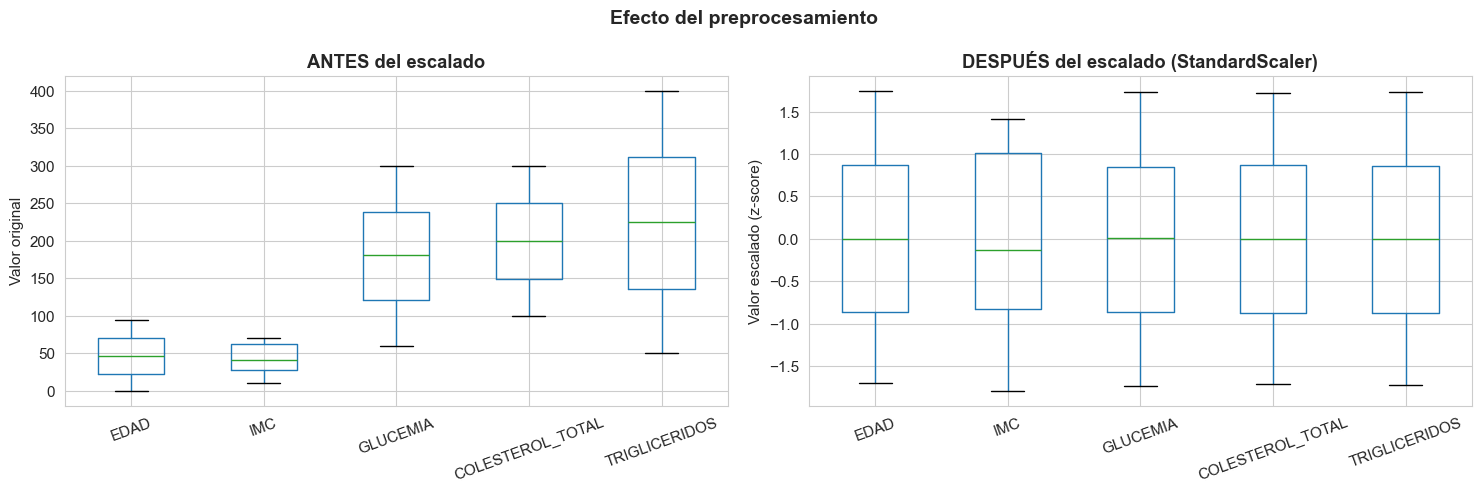

In [17]:
# Visualizar el efecto del escalado
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

X.boxplot(ax=axes[0])
axes[0].set_title('ANTES del escalado', fontweight='bold')
axes[0].set_ylabel('Valor original')
axes[0].tick_params(axis='x', rotation=20)

X_scaled_df.boxplot(ax=axes[1])
axes[1].set_title('DESPUÉS del escalado (StandardScaler)', fontweight='bold')
axes[1].set_ylabel('Valor escalado (z-score)')
axes[1].tick_params(axis='x', rotation=20)

plt.suptitle('Efecto del preprocesamiento', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

**Interpretación:** antes del escalado, los triglicéridos y la glucemia tenían valores mucho más grandes que el IMC o la edad. Después, las 5 variables están en la misma escala, así que K-Means les da la misma importancia.

---
## Paso 6: Implementación de K-Means

### ¿Cómo elegir el número de clusters K?

**1. Método del codo**
- Probamos K de 2 a 10 y calculamos el **WCSS** (qué tan dispersos están los puntos dentro de cada grupo).
- Buscamos el **"codo"**: el punto donde agregar más clusters ya no mejora mucho.

**2. Silhouette Score**
- Mide qué tan separados están los clusters.
- Va de **-1 a 1**; más cerca de 1 es mejor.

In [18]:
# Método del codo
print("Calculando WCSS para K = 2 a 10...")

wcss = []                # WCSS de cada K
k_range = range(2, 11)

for k in k_range:
    kmeans_temp = KMeans(n_clusters=k, random_state=SEMILLA, n_init=10)   # 10 inicios distintos
    kmeans_temp.fit(X_scaled)
    wcss.append(kmeans_temp.inertia_)   # inertia_ = WCSS

print("Cálculo completado\n")
for k, w in zip(k_range, wcss):
    print(f"   K={k:2d}: WCSS = {w:,.0f}")

Calculando WCSS para K = 2 a 10...
Cálculo completado

   K= 2: WCSS = 42,429
   K= 3: WCSS = 37,385
   K= 4: WCSS = 34,053
   K= 5: WCSS = 31,098
   K= 6: WCSS = 28,760
   K= 7: WCSS = 26,965
   K= 8: WCSS = 25,311
   K= 9: WCSS = 23,715
   K=10: WCSS = 22,384


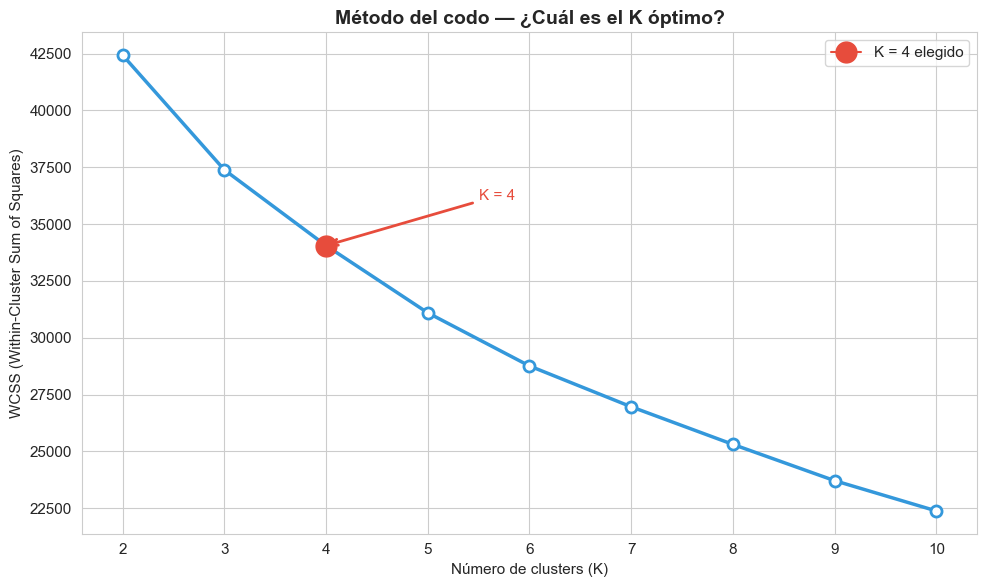

In [19]:
# Gráfico del codo
plt.figure(figsize=(10, 6))
plt.plot(list(k_range), wcss, marker='o', linewidth=2.5, color='#3498db',
         markersize=8, markerfacecolor='white', markeredgewidth=2)

# Resaltar K = 4 (índice 2 de la lista)
plt.plot(4, wcss[2], marker='o', markersize=15, color='#e74c3c', zorder=5, label='K = 4 elegido')
plt.annotate('K = 4', xy=(4, wcss[2]), xytext=(5.5, wcss[2] + (wcss[0] - wcss[-1]) * 0.1),
             fontsize=11, color='#e74c3c', arrowprops=dict(arrowstyle='->', color='#e74c3c', lw=2))

plt.title('Método del codo — ¿Cuál es el K óptimo?', fontsize=14, fontweight='bold')
plt.xlabel('Número de clusters (K)')
plt.ylabel('WCSS (Within-Cluster Sum of Squares)')
plt.xticks(list(k_range))
plt.legend()
plt.tight_layout()
plt.show()

**Interpretación:** la curva baja de forma suave y **no tiene un codo marcado**. La caída más fuerte está entre K = 2 y K = 4; desde ahí baja más lento. Por eso K = 4 es una opción razonable.

In [20]:
# Silhouette Score para K = 2 a 10
print("Calculando Silhouette Score para K = 2 a 10...")

silhouette_scores = []
for k in k_range:
    kmeans_temp = KMeans(n_clusters=k, random_state=SEMILLA, n_init=10)
    labels = kmeans_temp.fit_predict(X_scaled)
    silhouette_scores.append(silhouette_score(X_scaled, labels))

print("Cálculo completado\n")
for k, s in zip(k_range, silhouette_scores):
    barra = '█' * int(s * 100)
    print(f"   K={k:2d}: {s:.4f}  {barra}")

Calculando Silhouette Score para K = 2 a 10...
Cálculo completado

   K= 2: 0.1499  ██████████████
   K= 3: 0.1450  ██████████████
   K= 4: 0.1471  ██████████████
   K= 5: 0.1496  ██████████████
   K= 6: 0.1554  ███████████████
   K= 7: 0.1562  ███████████████
   K= 8: 0.1623  ████████████████
   K= 9: 0.1674  ████████████████
   K=10: 0.1729  █████████████████


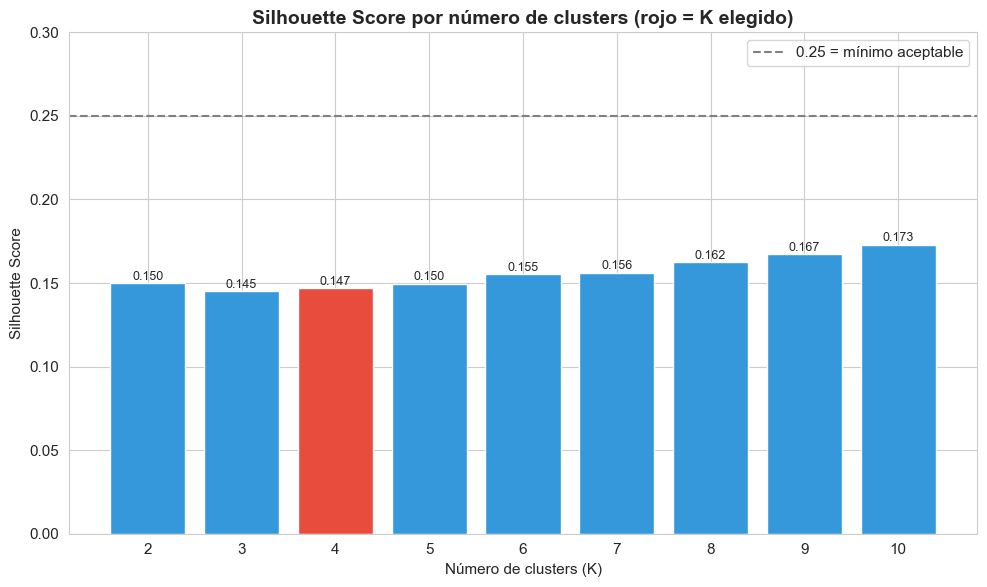

K con mayor Silhouette: 10 (0.173)
Silhouette con K = 4:   0.147
Usaremos K = 4 considerando el codo y la facilidad de interpretación


In [21]:
# Gráfico de Silhouette Score
mejor_k = list(k_range)[silhouette_scores.index(max(silhouette_scores))]

plt.figure(figsize=(10, 6))
barras = plt.bar(list(k_range), silhouette_scores,
                 color=['#e74c3c' if k == 4 else '#3498db' for k in k_range], edgecolor='white')
for b, s in zip(barras, silhouette_scores):
    plt.text(b.get_x() + b.get_width() / 2, b.get_height() + 0.002, f'{s:.3f}', ha='center', fontsize=9)

plt.axhline(0.25, color='gray', linestyle='--', label='0.25 = mínimo aceptable')
plt.title('Silhouette Score por número de clusters (rojo = K elegido)', fontsize=14, fontweight='bold')
plt.xlabel('Número de clusters (K)')
plt.ylabel('Silhouette Score')
plt.xticks(list(k_range))
plt.ylim(0, 0.3)
plt.legend()
plt.tight_layout()
plt.show()

print(f"K con mayor Silhouette: {mejor_k} ({max(silhouette_scores):.3f})")
print(f"Silhouette con K = 4:   {silhouette_scores[2]:.3f}")
print("Usaremos K = 4 considerando el codo y la facilidad de interpretación")

**Interpretación:** el Silhouette es casi el mismo para todos los K (entre 0.145 y 0.173), y siempre está por debajo de 0.25. Con K = 10 sube un poco solo porque los grupos se vuelven más pequeños, no porque sean mejores. Elegimos **K = 4** porque el Silhouette es casi igual y 4 grupos se pueden interpretar mejor.

### Entrenar el modelo K-Means con K = 4

Parámetros:
- `n_clusters=4`: queremos 4 grupos de pacientes.
- `random_state=42`: semilla para que el resultado sea siempre el mismo.
- `n_init=10`: el algoritmo se ejecuta 10 veces con distintos centros iniciales y se queda con el mejor.

In [22]:
# Entrenar el modelo K-Means
K_OPTIMO = 4
kmeans = KMeans(n_clusters=K_OPTIMO, random_state=SEMILLA, n_init=10)
df['CLUSTER'] = kmeans.fit_predict(X_scaled)   # grupo de cada paciente

print(f"Modelo K-Means entrenado con K = {K_OPTIMO}")
print(f"   WCSS final: {kmeans.inertia_:,.2f}\n")
print("Distribución de pacientes por cluster:")
conteo = df['CLUSTER'].value_counts().sort_index()
for cluster, n in conteo.items():
    pct = n / len(df) * 100
    print(f"   Cluster {cluster}: {n:5,} pacientes ({pct:.1f}%) {'█' * int(pct / 2)}")

Modelo K-Means entrenado con K = 4
   WCSS final: 34,052.60

Distribución de pacientes por cluster:
   Cluster 0: 2,168 pacientes (21.7%) ██████████
   Cluster 1: 2,808 pacientes (28.1%) ██████████████
   Cluster 2: 2,772 pacientes (27.7%) █████████████
   Cluster 3: 2,252 pacientes (22.5%) ███████████


### Nombre de cada cluster

Revisamos el **centro (promedio) de cada cluster** y le damos un nombre. Los nombres se asignan con reglas, para que no cambien si K-Means numera los grupos en otro orden:
- el cluster con **mayor edad** = adultos mayores
- el cluster con **menor edad** = jóvenes
- de los dos restantes, el de **mayor colesterol** = colesterol alto

In [23]:
# Centro de cada cluster en valores reales
centros = df.groupby('CLUSTER')[features].mean().round(1)

orden_edad = centros['EDAD'].sort_values().index
jovenes, mayores = orden_edad[0], orden_edad[-1]
medios = centros.loc[orden_edad[1:3], 'COLESTEROL_TOTAL'].sort_values().index

NOMBRES_CLUSTER = {
    jovenes:   'Jóvenes con IMC extremo',
    medios[0]: 'Adultos con colesterol normal',
    medios[1]: 'Adultos con colesterol alto',
    mayores:   'Adultos mayores con IMC extremo',
}
ORDEN = ['Jóvenes con IMC extremo', 'Adultos con colesterol normal',
         'Adultos con colesterol alto', 'Adultos mayores con IMC extremo']
COLORES = dict(zip(ORDEN, ['#f39c12', '#2ecc71', '#e74c3c', '#3498db']))

df['SEGMENTO'] = pd.Categorical(df['CLUSTER'].map(NOMBRES_CLUSTER), categories=ORDEN, ordered=True)

for c in sorted(NOMBRES_CLUSTER):
    print(f"   Cluster {c} -> {NOMBRES_CLUSTER[c]}")

   Cluster 0 -> Jóvenes con IMC extremo
   Cluster 1 -> Adultos con colesterol alto
   Cluster 2 -> Adultos con colesterol normal
   Cluster 3 -> Adultos mayores con IMC extremo


---
## Paso 7: Visualización de los clusters

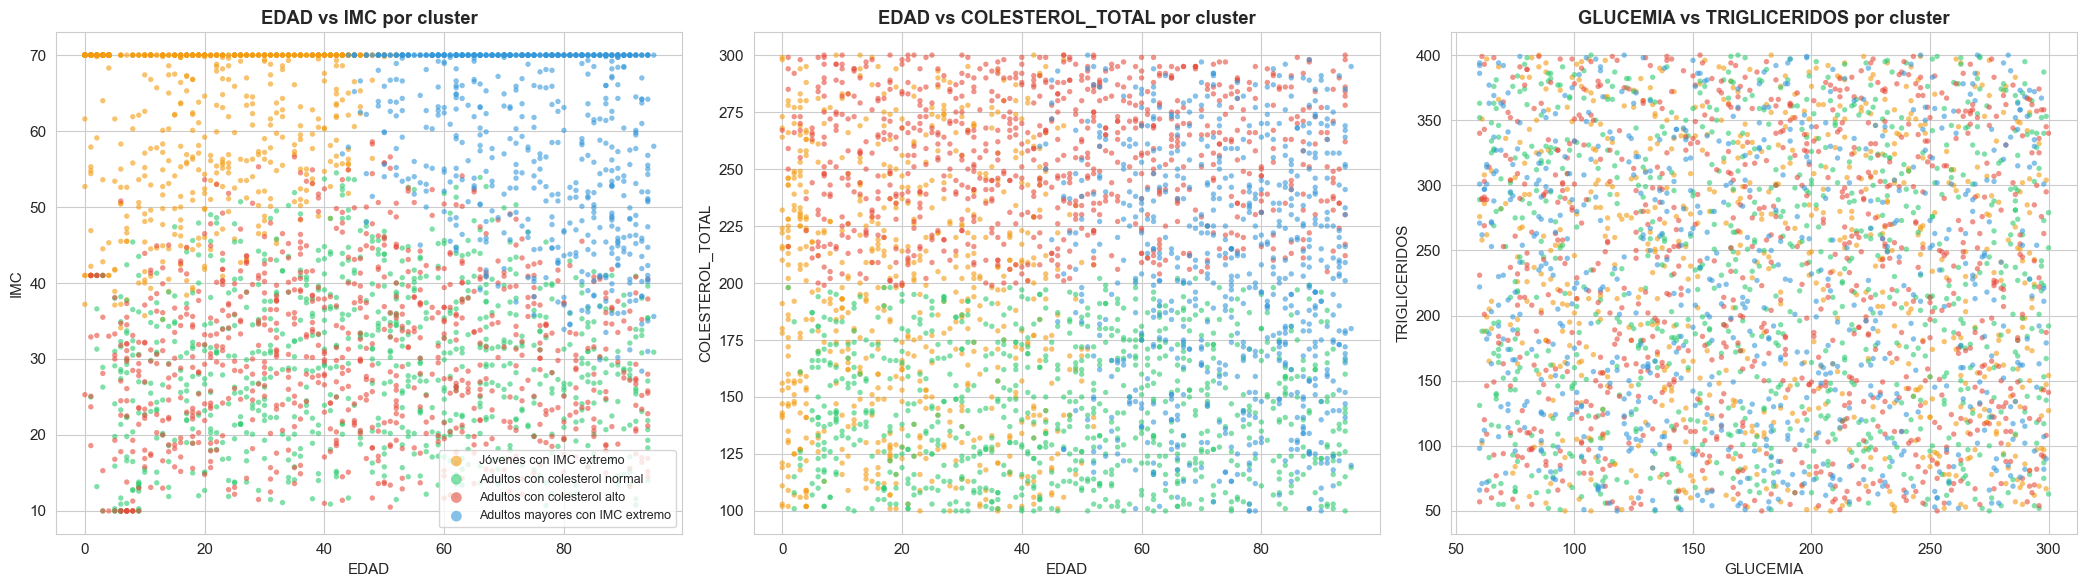

In [24]:
# Gráfico 1: dispersión con el nombre de cada cluster
muestra = df.sample(3000, random_state=SEMILLA)   # muestra para que el gráfico se vea claro
pares = [('EDAD', 'IMC'), ('EDAD', 'COLESTEROL_TOTAL'), ('GLUCEMIA', 'TRIGLICERIDOS')]

fig, axes = plt.subplots(1, 3, figsize=(21, 6))
for ax, (vx, vy) in zip(axes, pares):
    for nombre in ORDEN:
        datos = muestra[muestra['SEGMENTO'] == nombre]
        ax.scatter(datos[vx], datos[vy], c=COLORES[nombre], label=nombre,
                   alpha=0.6, s=15, edgecolors='none')
    ax.set_title(f'{vx} vs {vy} por cluster', fontweight='bold')
    ax.set_xlabel(vx)
    ax.set_ylabel(vy)
axes[0].legend(fontsize=9, markerscale=2)
plt.tight_layout()
plt.show()

**Interpretación:**
- **EDAD vs IMC:** se ve claramente la separación. Arriba a la izquierda están los jóvenes con IMC extremo, arriba a la derecha los adultos mayores con IMC extremo y abajo los adultos con IMC más bajo.
- **EDAD vs COLESTEROL:** los dos grupos de adultos se separan por colesterol: alto (rojo) y normal (verde).
- **GLUCEMIA vs TRIGLICÉRIDOS:** los colores están mezclados. Estas dos variables **no separan** los grupos.

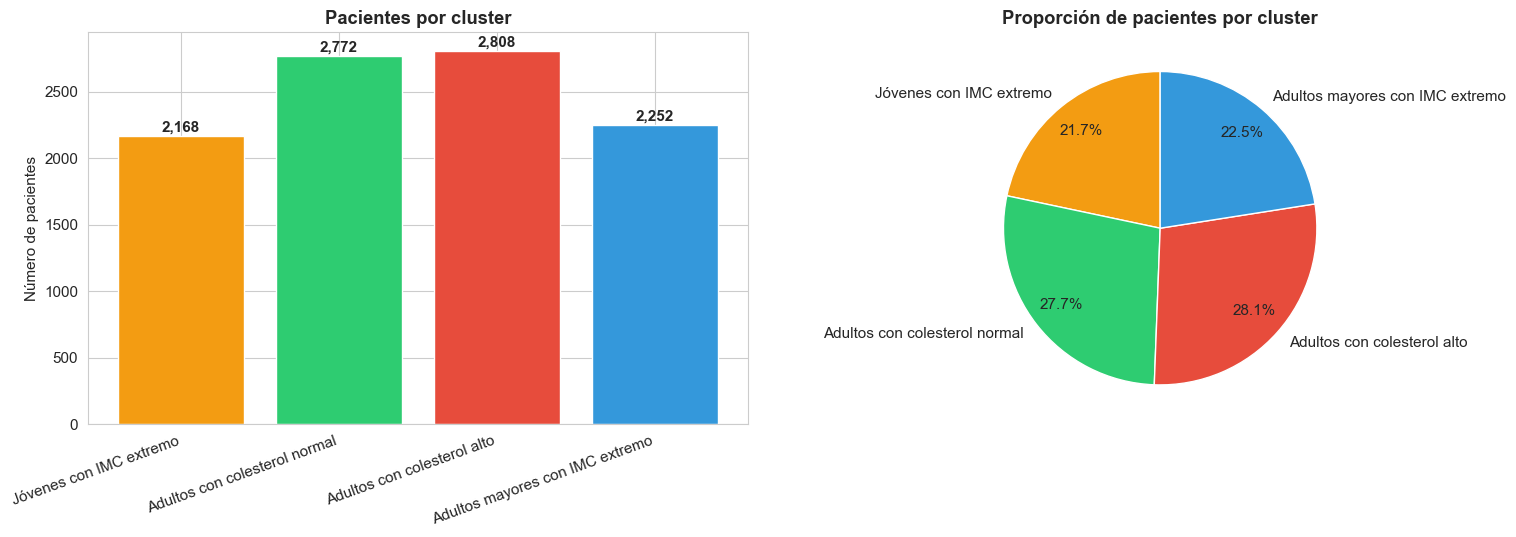

In [25]:
# Gráfico 2: distribución de pacientes por cluster
conteo_clusters = df['SEGMENTO'].value_counts().reindex(ORDEN)
colores = [COLORES[n] for n in ORDEN]

fig, axes = plt.subplots(1, 2, figsize=(16, 5.5))
axes[0].bar(range(K_OPTIMO), conteo_clusters.values, color=colores, edgecolor='white')
axes[0].set_xticks(range(K_OPTIMO))
axes[0].set_xticklabels(ORDEN, rotation=20, ha='right')
axes[0].set_title('Pacientes por cluster', fontweight='bold')
axes[0].set_ylabel('Número de pacientes')
for i, v in enumerate(conteo_clusters.values):
    axes[0].text(i, v + 30, f'{v:,}', ha='center', fontweight='bold')

axes[1].pie(conteo_clusters.values, labels=ORDEN, colors=colores,
            autopct='%1.1f%%', startangle=90, pctdistance=0.8)
axes[1].set_title('Proporción de pacientes por cluster', fontweight='bold')
plt.tight_layout()
plt.show()

**Interpretación:** los 4 grupos tienen tamaños parecidos (entre 22 % y 28 %). Ninguno es demasiado pequeño, así que todos se pueden analizar.

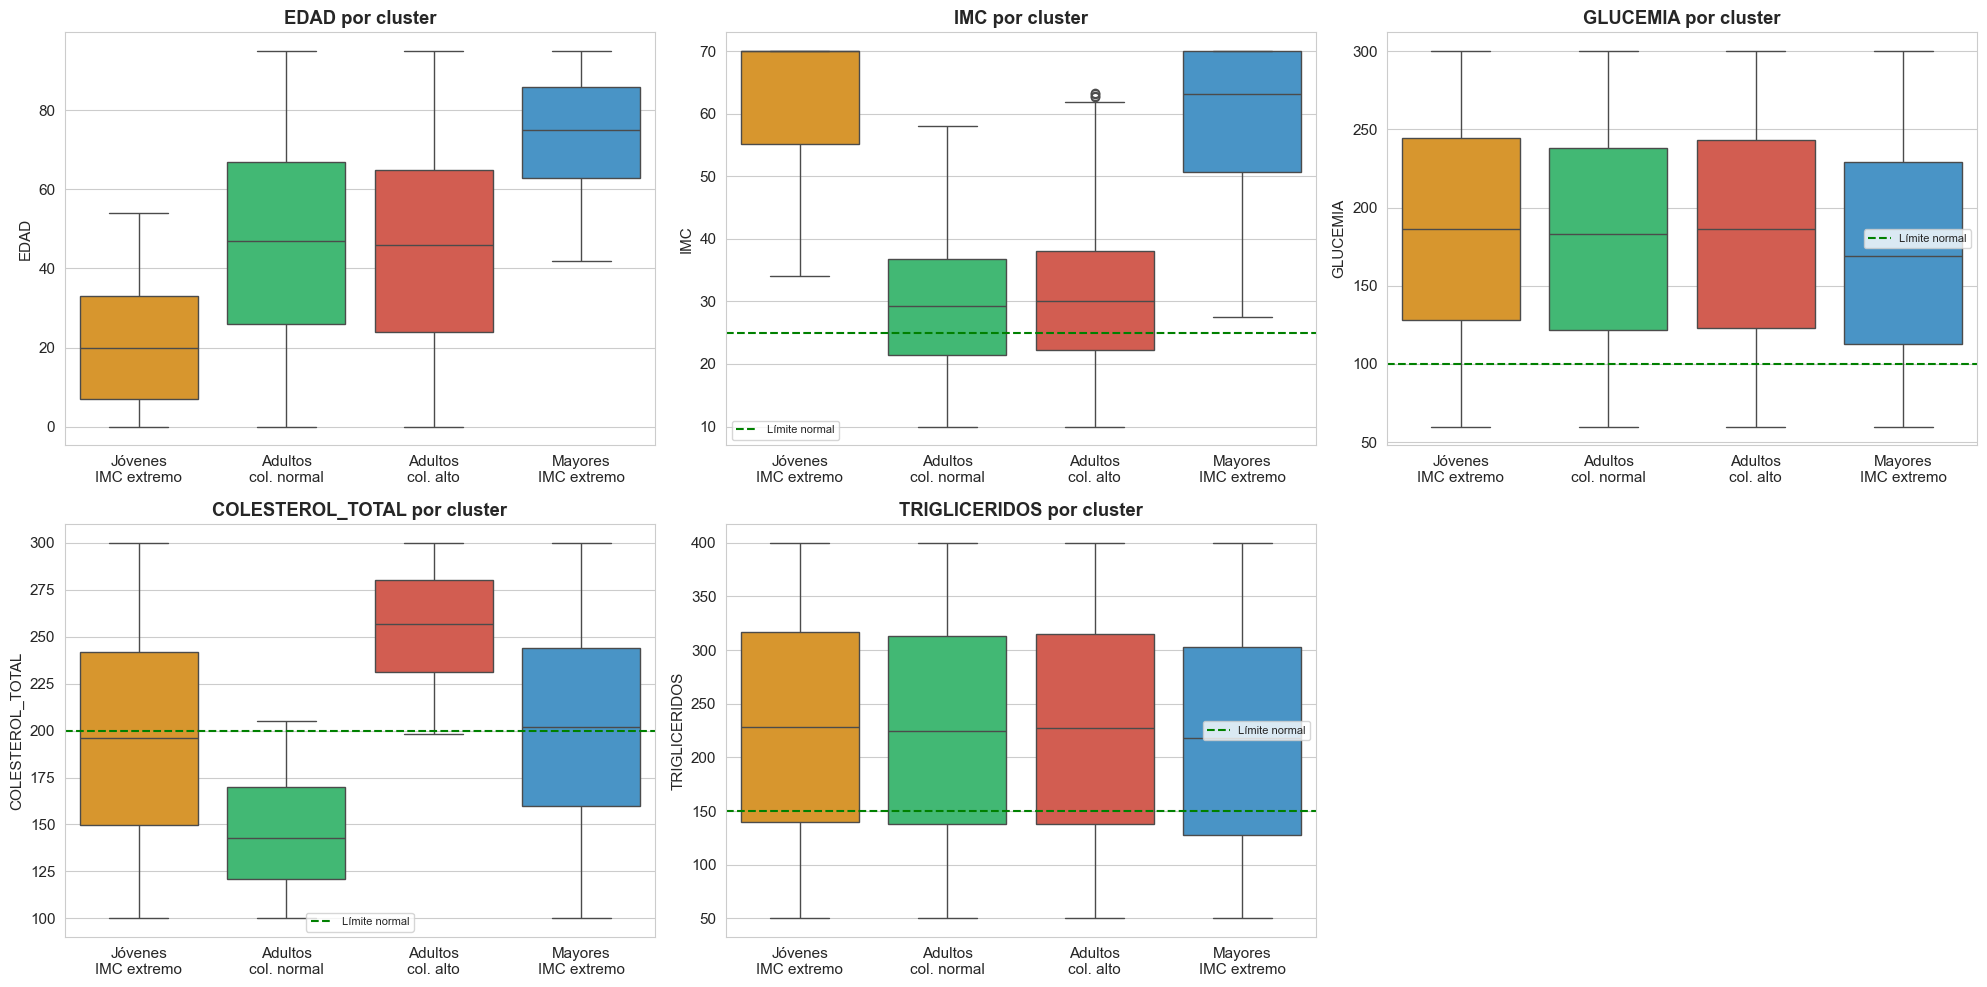

In [26]:
# Gráfico 3: boxplots de cada variable por cluster
fig, axes = plt.subplots(2, 3, figsize=(20, 10))
for ax, var in zip(axes.flat, features):
    sns.boxplot(data=df, x='SEGMENTO', y=var, order=ORDEN, palette=COLORES, ax=ax)
    ax.set_title(f'{var} por cluster', fontweight='bold')
    ax.set_xlabel('')
    ax.set_xticklabels(['Jóvenes\nIMC extremo', 'Adultos\ncol. normal',
                        'Adultos\ncol. alto', 'Mayores\nIMC extremo'])
    if var in limite_normal:
        ax.axhline(limite_normal[var], color='green', linestyle='--', label='Límite normal')
        ax.legend(fontsize=8)
axes.flat[-1].axis('off')   # el sexto espacio queda vacío
plt.tight_layout()
plt.show()

**Interpretación:**
- **EDAD, IMC y COLESTEROL** son las variables que diferencian a los grupos: sus cajas están en niveles distintos.
- **GLUCEMIA y TRIGLICÉRIDOS** tienen cajas casi iguales en los 4 grupos, y todas están por encima de la línea verde (límite normal).
- Los dos grupos de IMC extremo tienen la caja casi pegada a 70, por los valores imposibles que recortamos.

---
## Paso 8: Perfilado de clusters

El perfilado **describe** las características promedio de cada cluster para darle un **nombre y personalidad** que ayude a tomar decisiones en el hospital.

In [27]:
# Perfil estadístico de cada cluster
cluster_profile = df.groupby('SEGMENTO')[features].mean().round(2)
print("Perfil promedio de cada cluster:\n")
print(cluster_profile.to_string())

Perfil promedio de cada cluster:

                                  EDAD    IMC  GLUCEMIA  COLESTEROL_TOTAL  TRIGLICERIDOS
SEGMENTO                                                                                
Jóvenes con IMC extremo          20.65  62.48    185.09            195.79         227.26
Adultos con colesterol normal    46.96  29.27    180.58            145.70         225.69
Adultos con colesterol alto      45.58  30.35    183.00            255.05         226.70
Adultos mayores con IMC extremo  73.90  59.47    171.99            201.54         218.61


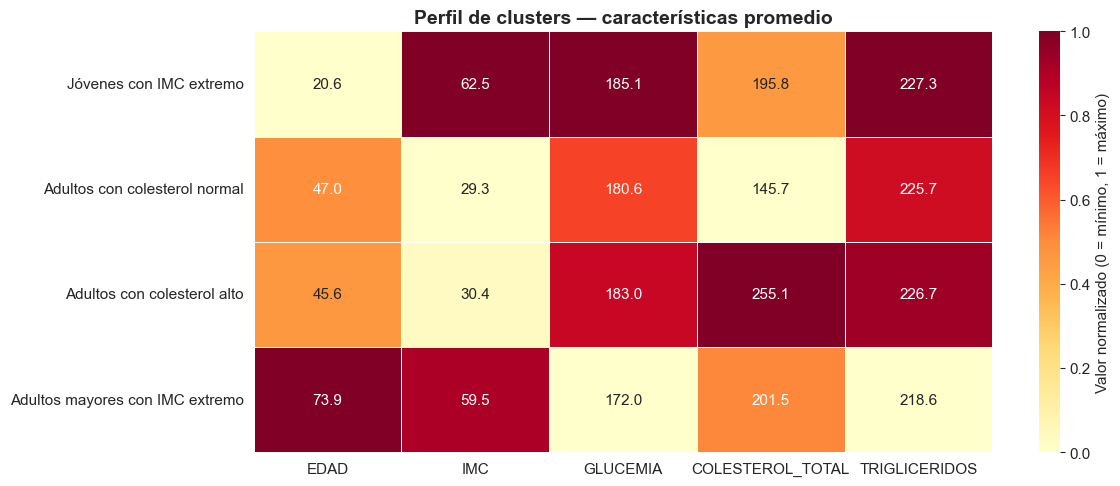

In [28]:
# Heatmap del perfil (0 = valor más bajo, 1 = más alto entre los clusters)
profile_norm = (cluster_profile - cluster_profile.min()) / (cluster_profile.max() - cluster_profile.min())

plt.figure(figsize=(12, 5))
sns.heatmap(profile_norm, annot=cluster_profile, fmt='.1f', cmap='YlOrRd', linewidths=0.5,
            cbar_kws={'label': 'Valor normalizado (0 = mínimo, 1 = máximo)'})
plt.title('Perfil de clusters — características promedio', fontsize=14, fontweight='bold')
plt.ylabel('')
plt.tight_layout()
plt.show()

In [29]:
# Interpretación de los clusters (comparando con los valores normales)
print("INTERPRETACIÓN DE LOS CLUSTERS")
print("=" * 55)
for nombre in ORDEN:
    p = cluster_profile.loc[nombre]
    n = (df['SEGMENTO'] == nombre).sum()
    print(f"\n  {nombre} — {n:,} pacientes ({n / len(df) * 100:.1f}%)")
    print(f"  Edad promedio          : {p['EDAD']:7.1f} años")
    print(f"  IMC promedio           : {p['IMC']:7.1f}   (normal 18.5 - 24.9)")
    print(f"  Glucemia promedio      : {p['GLUCEMIA']:7.1f}   (normal 70 - 99)")
    print(f"  Colesterol promedio    : {p['COLESTEROL_TOTAL']:7.1f}   (normal < 200)")
    print(f"  Triglicéridos promedio : {p['TRIGLICERIDOS']:7.1f}   (normal < 150)")

INTERPRETACIÓN DE LOS CLUSTERS

  Jóvenes con IMC extremo — 2,168 pacientes (21.7%)
  Edad promedio          :    20.6 años
  IMC promedio           :    62.5   (normal 18.5 - 24.9)
  Glucemia promedio      :   185.1   (normal 70 - 99)
  Colesterol promedio    :   195.8   (normal < 200)
  Triglicéridos promedio :   227.3   (normal < 150)

  Adultos con colesterol normal — 2,772 pacientes (27.7%)
  Edad promedio          :    47.0 años
  IMC promedio           :    29.3   (normal 18.5 - 24.9)
  Glucemia promedio      :   180.6   (normal 70 - 99)
  Colesterol promedio    :   145.7   (normal < 200)
  Triglicéridos promedio :   225.7   (normal < 150)

  Adultos con colesterol alto — 2,808 pacientes (28.1%)
  Edad promedio          :    45.6 años
  IMC promedio           :    30.4   (normal 18.5 - 24.9)
  Glucemia promedio      :   183.0   (normal 70 - 99)
  Colesterol promedio    :   255.1   (normal < 200)
  Triglicéridos promedio :   226.7   (normal < 150)

  Adultos mayores con IMC extre

### Etiquetas de los clusters

| Nombre | Descripción |
|---|---|
| **Jóvenes con IMC extremo** | 21 años e IMC 62.5 en promedio. El 46 % son menores de edad, con 102 kg y 1.13 m en promedio. No es un perfil médico real: es el efecto de pesos y estaturas generados por separado. |
| **Adultos con colesterol normal** | 47 años, colesterol 146 e IMC 29. Es el grupo más sano en grasas, aunque igual tiene la glucemia alta (181). |
| **Adultos con colesterol alto** | 46 años, colesterol 255 e IMC 30. Tienen riesgo cardiovascular. Es el grupo con más sentido médico. |
| **Adultos mayores con IMC extremo** | 74 años e IMC 59.5. El 93 % tiene obesidad mórbida (IMC de 40 o más), algo muy improbable en la realidad. |

### ¿Cómo usaría el hospital esta segmentación?

- **Jóvenes con IMC extremo:** revisar cómo se registran el peso y la talla; programa de nutrición infantil y juvenil.
- **Adultos con colesterol normal:** controles de rutina; vigilar la glucemia.
- **Adultos con colesterol alto:** control de lípidos, dieta y evaluación cardiológica.
- **Adultos mayores con IMC extremo:** verificar los datos; control geriátrico de peso, presión y glucosa.

---
## Paso 9: Comparación de los clusters con otras variables

Usamos variables que **no entraron al modelo** para ver si los grupos se diferencian en algo importante para el hospital. Aquí respondemos la pregunta del proyecto: **¿algún grupo tiene más complicaciones?**

In [30]:
nivel_bajo = df['NIVEL_SOCIOECONOMICO'].str.contains('Nivel 1|Nivel 2')   # pobreza o extrema pobreza

comparacion = df.assign(NIVEL_BAJO=nivel_bajo).groupby('SEGMENTO').agg(
    Pacientes=('CLUSTER', 'size'),
    Complicacion_pct=('TARGET_COMPLICACION', 'mean'),
    Internados_pct=('INTERNADO', 'mean'),
    Fallecidos_pct=('ESTADO_PACIENTE', lambda s: (s == 'Fallecido').mean()),
    Criticos_pct=('ESTADO_PACIENTE', lambda s: (s == 'Critico').mean()),
    Pobreza_pct=('NIVEL_BAJO', 'mean'),
    Enfermedades_prom=('NUM_ENFERMEDADES', 'mean'),
)
for col in comparacion.columns:
    if col.endswith('_pct'):
        comparacion[col] = comparacion[col] * 100   # pasar a porcentaje
comparacion.round(1)

,Pacientes,Complicacion_pct,Internados_pct,Fallecidos_pct,Criticos_pct,Pobreza_pct,Enfermedades_prom
SEGMENTO,,,,,,,
Jóvenes con IMC extremo,2168,87.6,10.7,1.8,5.2,37.3,2.5
Adultos con colesterol normal,2772,88.2,11.4,2.1,5.6,33.9,2.5
Adultos con colesterol alto,2808,87.6,11.6,2.1,5.4,36.7,2.5
Adultos mayores con IMC extremo,2252,87.9,12.3,2.0,3.9,36.3,2.5


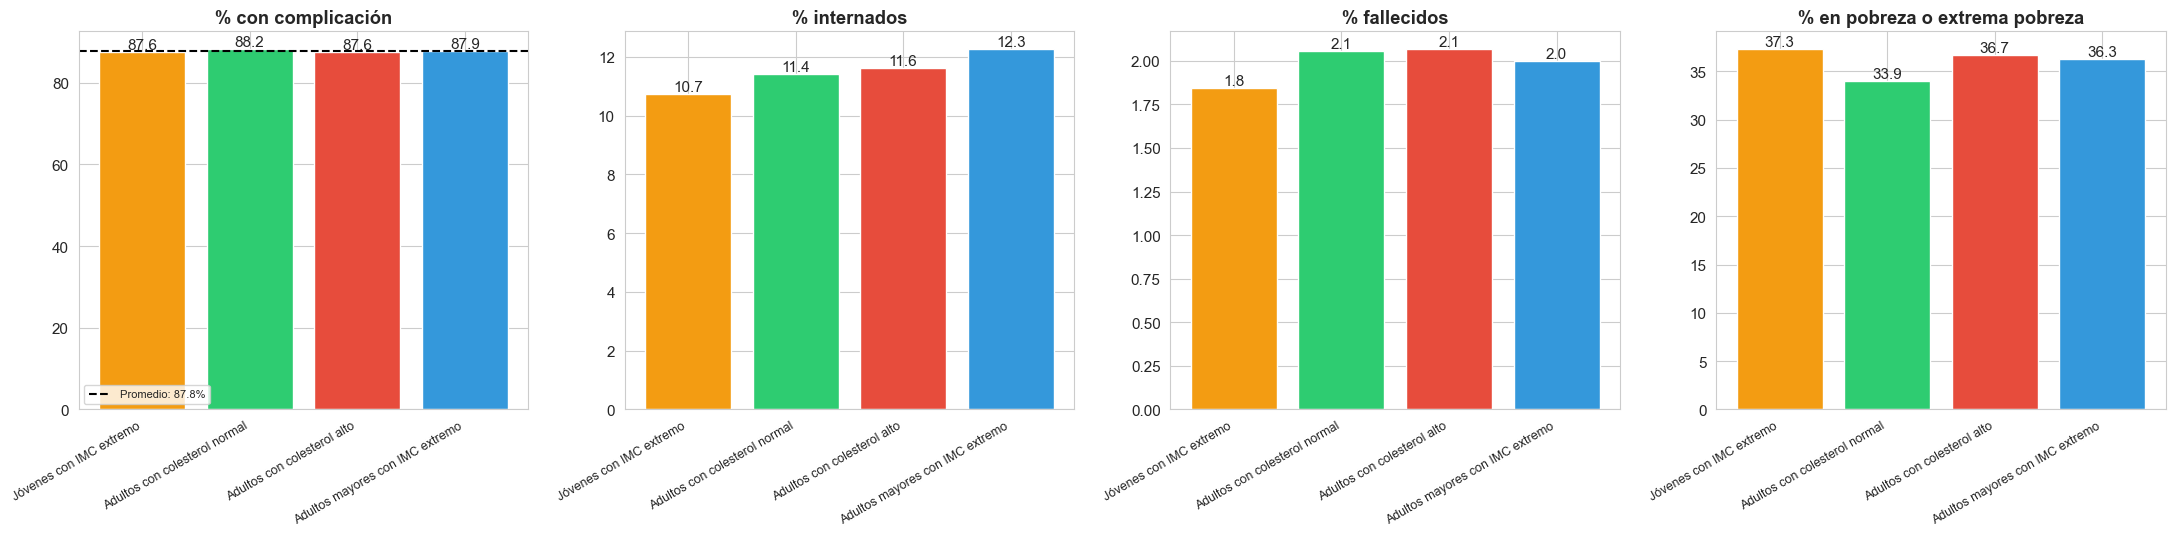

In [31]:
graficos = [('Complicacion_pct', '% con complicación'), ('Internados_pct', '% internados'),
            ('Fallecidos_pct', '% fallecidos'), ('Pobreza_pct', '% en pobreza o extrema pobreza')]

fig, axes = plt.subplots(1, 4, figsize=(22, 5.5))
for ax, (col, titulo) in zip(axes, graficos):
    ax.bar(range(K_OPTIMO), comparacion[col], color=colores)
    ax.set_xticks(range(K_OPTIMO))
    ax.set_xticklabels(ORDEN, rotation=30, ha='right', fontsize=9)
    ax.set_title(titulo, fontweight='bold')
    for i, v in enumerate(comparacion[col]):
        ax.text(i, v, f'{v:.1f}', ha='center', va='bottom')
axes[0].axhline(tasa_global, color='black', linestyle='--', label=f'Promedio: {tasa_global:.1f}%')
axes[0].legend(fontsize=8)
plt.tight_layout()
plt.show()

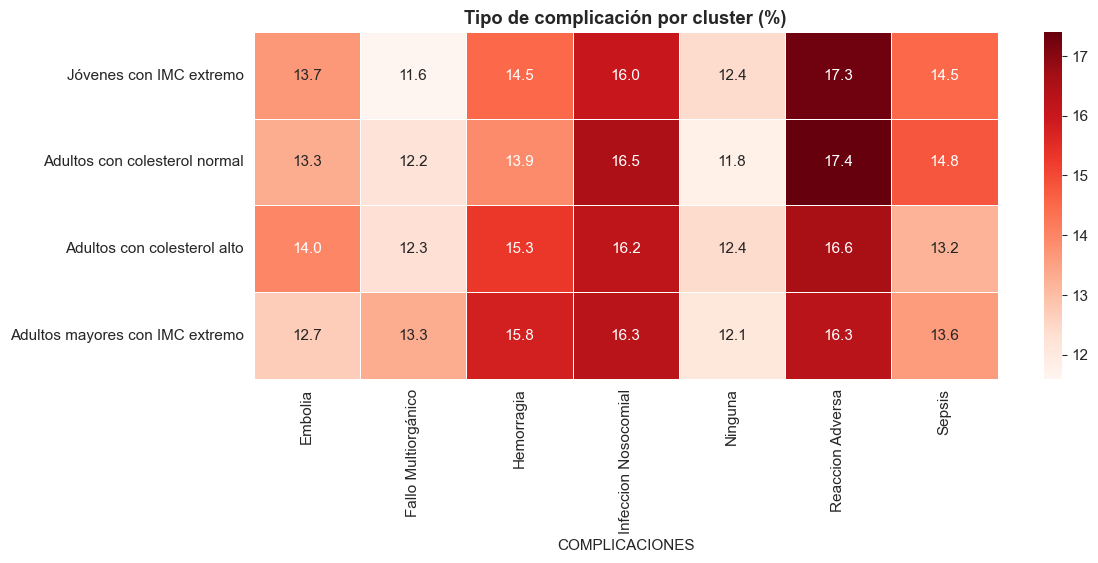

In [32]:
# Tipo de complicación dentro de cada cluster (% por fila)
tipo_compl = pd.crosstab(df['SEGMENTO'], df['COMPLICACIONES'], normalize='index').mul(100).round(1)

plt.figure(figsize=(12, 4.5))
sns.heatmap(tipo_compl, annot=True, fmt='.1f', cmap='Reds', linewidths=0.5)
plt.title('Tipo de complicación por cluster (%)', fontweight='bold')
plt.ylabel('')
plt.show()

In [33]:
# ¿Los pacientes con IMC extremo tienen diagnóstico de obesidad?
df['DX_OBESIDAD'] = df['ENFERMEDADES'].str.contains('Obesidad').astype(int)
df.groupby('SEGMENTO').agg(IMC_promedio=('IMC', 'mean'),
                           Con_diagnostico_obesidad_pct=('DX_OBESIDAD', lambda s: s.mean() * 100)).round(1)

,IMC_promedio,Con_diagnostico_obesidad_pct
SEGMENTO,,
Jóvenes con IMC extremo,62.5,4.9
Adultos con colesterol normal,29.3,5.1
Adultos con colesterol alto,30.4,4.8
Adultos mayores con IMC extremo,59.5,4.4


**Interpretación:**
- **Complicaciones:** los 4 grupos tienen casi la misma tasa (87.6 % a 88.2 %), igual al promedio (87.8 %). El tipo de complicación también se reparte casi igual. El perfil metabólico **no explica** quién tiene complicaciones.
- **Internación:** sube un poco con la edad (10.7 % en jóvenes y 12.3 % en adultos mayores). Es la única tendencia lógica, pero la diferencia es pequeña.
- **Fallecidos:** los adultos mayores (2.0 %) no tienen más fallecidos que los adultos (2.1 %). En la realidad, la mortalidad sube mucho con la edad.
- **Obesidad:** los grupos con IMC promedio de 60 tienen el mismo porcentaje de diagnóstico de obesidad (≈ 5 %) que los grupos con IMC de 30. Si los datos fueran reales, casi todos tendrían ese diagnóstico.

---
## Paso 10: Evaluación y métricas del modelo

En clustering no hay una "respuesta correcta" para comparar. Las métricas miden la **calidad interna** de los grupos:

| Métrica | Qué mide | Mejor valor |
|---|---|---|
| **WCSS / Inercia** | Qué tan compactos son los clusters | Más bajo |
| **Silhouette Score** | Separación entre clusters | Más cerca de 1 |

In [34]:
# Evaluación del modelo final
silhouette_final = silhouette_score(X_scaled, kmeans.labels_)

print(f"MÉTRICAS DEL MODELO K-MEANS (K={K_OPTIMO})")
print("=" * 45)
print(f"  Número de clusters : {K_OPTIMO}")
print(f"  WCSS (Inercia)     : {kmeans.inertia_:,.2f}")
print(f"  Silhouette Score   : {silhouette_final:.4f}")
print(f"  Iteraciones usadas : {kmeans.n_iter_}")

if silhouette_final > 0.7:
    interpretacion = "Excelente — clusters muy bien definidos"
elif silhouette_final > 0.5:
    interpretacion = "Bueno — clusters razonablemente definidos"
elif silhouette_final > 0.25:
    interpretacion = "Aceptable — hay superposición entre clusters"
else:
    interpretacion = "Débil — los clusters se solapan mucho"
print(f"  Interpretación     : {interpretacion}")

MÉTRICAS DEL MODELO K-MEANS (K=4)
  Número de clusters : 4
  WCSS (Inercia)     : 34,052.60
  Silhouette Score   : 0.1471
  Iteraciones usadas : 43
  Interpretación     : Débil — los clusters se solapan mucho


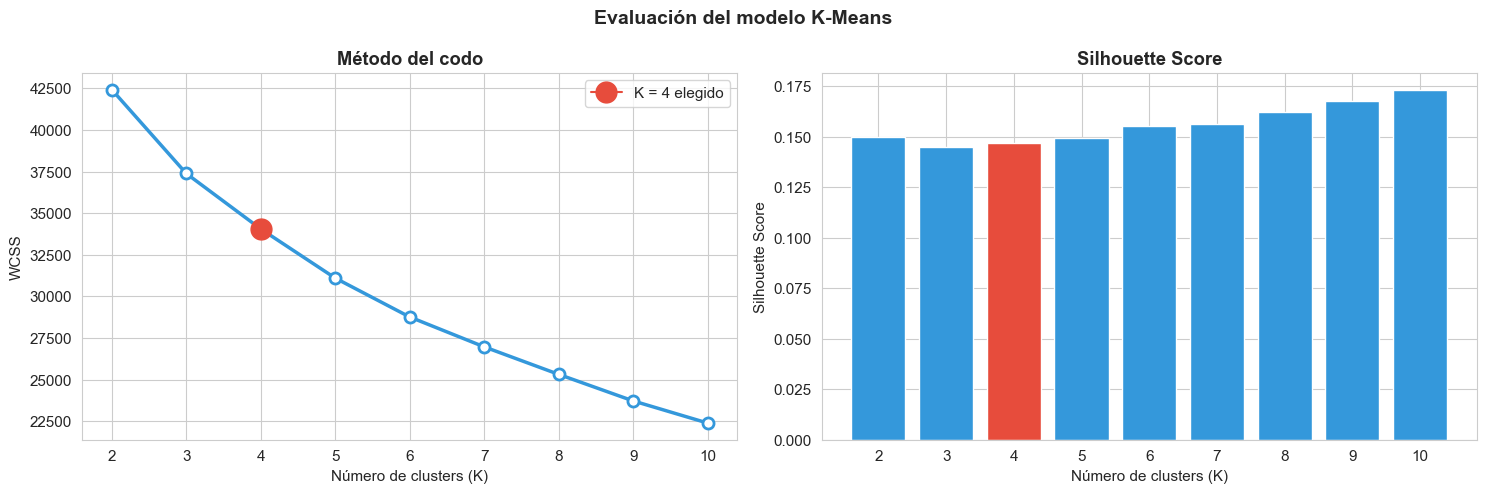

In [35]:
# Visualización final: codo + silhouette
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

axes[0].plot(list(k_range), wcss, marker='o', linewidth=2.5, color='#3498db',
             markersize=8, markerfacecolor='white', markeredgewidth=2)
axes[0].plot(4, wcss[2], marker='o', markersize=15, color='#e74c3c', zorder=5, label='K = 4 elegido')
axes[0].set_title('Método del codo', fontweight='bold')
axes[0].set_xlabel('Número de clusters (K)')
axes[0].set_ylabel('WCSS')
axes[0].set_xticks(list(k_range))
axes[0].legend()

axes[1].bar(list(k_range), silhouette_scores,
            color=['#e74c3c' if k == K_OPTIMO else '#3498db' for k in k_range], edgecolor='white')
axes[1].set_title('Silhouette Score', fontweight='bold')
axes[1].set_xlabel('Número de clusters (K)')
axes[1].set_ylabel('Silhouette Score')
axes[1].set_xticks(list(k_range))

plt.suptitle('Evaluación del modelo K-Means', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

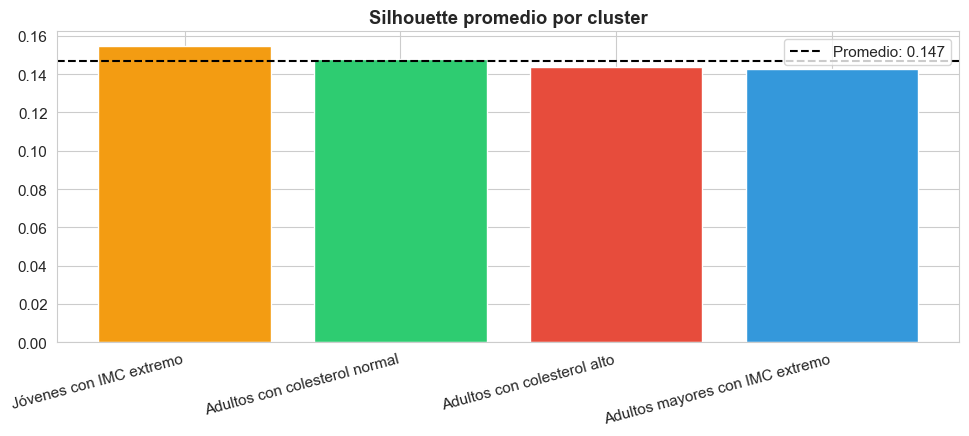

In [36]:
# Silhouette de cada cluster
sil_individual = pd.Series(silhouette_samples(X_scaled, kmeans.labels_))
sil_cluster = sil_individual.groupby(df['SEGMENTO'].values).mean().reindex(ORDEN)

plt.figure(figsize=(10, 4.5))
plt.bar(range(K_OPTIMO), sil_cluster.values, color=colores)
plt.xticks(range(K_OPTIMO), ORDEN, rotation=15, ha='right')
plt.axhline(silhouette_final, color='black', linestyle='--', label=f'Promedio: {silhouette_final:.3f}')
plt.title('Silhouette promedio por cluster', fontweight='bold')
plt.legend()
plt.tight_layout()
plt.show()

**Interpretación:** el Silhouette de **0.147** es **débil** (menor a 0.25): los grupos existen, pero se mezclan entre sí. Los 4 clusters tienen una calidad parecida. No es un error del modelo: pasa porque las variables no tienen relación entre ellas, como vimos en los Pasos 3 y 4.

---
## Paso 11: Conclusiones

1. **Se formaron 4 perfiles de pacientes:** jóvenes con IMC extremo, adultos con colesterol normal, adultos con colesterol alto y adultos mayores con IMC extremo. Las variables que más los separan son la edad, el IMC y el colesterol.
2. **Ningún grupo tiene más complicaciones** (todos ≈ 88 %). Esto coincide con la regresión logística y el árbol de decisión: las variables clínicas no explican las complicaciones.
3. **El dataset muestra inconsistencias graves:** hombres embarazados, mujeres con cáncer de próstata, niños de más de 30 kg, presiones imposibles, diagnósticos que no coinciden con el laboratorio y una edad calculada a 2026. Todo indica que los datos son **generados**, no de un hospital real.
4. **Recomendación:** para encontrar perfiles de riesgo útiles se necesitan datos clínicos reales. Con esta base, el principal hallazgo es la **falta de calidad de los datos**, lo que obliga a dudar de la fuente.

### Limitaciones de K-Means

| Limitación | Descripción |
|---|---|
| Hay que definir K | No siempre se sabe cuántos grupos buscar |
| Sensible a outliers | Un valor extremo (como un IMC de 418) puede mover un centro |
| Solo clusters esféricos | No detecta bien formas irregulares |
| Depende de la calidad de los datos | Si las variables no tienen relación entre sí, los grupos salen débiles |

In [39]:
# Resumen final
print("RESUMEN — K-Means: Perfiles de Pacientes Hospitalarios")
print("=" * 60)
print(f"  Dataset          : base_de_datos_medicina_complicaciones_modificada.xlsx")
print(f"  Registros        : {len(df):,} pacientes")
print(f"  Features usados  : {len(features)} ({', '.join(features)})")
print(f"  Algoritmo        : K-Means (scikit-learn)")
print(f"  K elegido        : {K_OPTIMO} clusters")
print(f"  WCSS             : {kmeans.inertia_:,.2f}")
print(f"  Silhouette Score : {silhouette_final:.4f}")
print(f"  Complicaciones   : {tasa_global:.2f}% (promedio general)")
print("\n  Distribución de clusters:")
for nombre in ORDEN:
    n = (df['SEGMENTO'] == nombre).sum()
    print(f"    {nombre:33s}: {n:5,} pacientes | "
          f"complicación {comparacion.loc[nombre, 'Complicacion_pct']:.1f}%")

RESUMEN — K-Means: Perfiles de Pacientes Hospitalarios
  Dataset          : base_de_datos_medicina_complicaciones_modificada.xlsx
  Registros        : 10,000 pacientes
  Features usados  : 5 (EDAD, IMC, GLUCEMIA, COLESTEROL_TOTAL, TRIGLICERIDOS)
  Algoritmo        : K-Means (scikit-learn)
  K elegido        : 4 clusters
  WCSS             : 34,052.60
  Silhouette Score : 0.1471
  Complicaciones   : 87.82% (promedio general)

  Distribución de clusters:
    Jóvenes con IMC extremo          : 2,168 pacientes | complicación 87.6%
    Adultos con colesterol normal    : 2,772 pacientes | complicación 88.2%
    Adultos con colesterol alto      : 2,808 pacientes | complicación 87.6%
    Adultos mayores con IMC extremo  : 2,252 pacientes | complicación 87.9%
